# Téléchargement d'images de peintures (Wikidata)

Ce notebook récupère 10 peintures avec leurs métadonnées, crée un DataFrame, et télécharge les images.

In [1]:
# Installation des bibliothèques nécessaires au projet.

%pip install SPARQLWrapper pandas scikit-learn requests matplotlib wordcloud pyspark
# SPARQLWrapper : permet d'interroger Wikidata avec des requêtes SPARQL.
# pandas : sert à manipuler les données sous forme de tableaux (DataFrame).
# scikit-learn : fournit les algorithmes de machine learning utilisés dans le projet.
# requests : permet d'envoyer des requêtes HTTP, notamment pour télécharger les images.
# matplotlib : sert à créer les graphiques et les visualisations.
# wordcloud : permet de générer un nuage de mots à partir des tags les plus fréquents.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os # Gère les fichiers et dossiers du système.
import sys # Donne accès à des informations système et à Python.
import time # Sert à gérer les temporisations et délais.
import requests # Permet d'envoyer des requêtes HTTP.
import shutil # Sert à copier et déplacer des fichiers.
import json # Permet de lire et écrire des fichiers JSON.
import random # Sert à générer de l'aléatoire pour la simulation.
import pandas as pd # Sert à manipuler les données sous forme de tableaux.
import matplotlib.pyplot as plt # Sert à créer les graphiques.
import numpy as np # Sert aux calculs numériques et tableaux.
import threading # Permet de gérer plusieurs tâches en parallèle.
import re # Sert à nettoyer ou analyser du texte avec des motifs.
import pprint # Permet d'afficher les données de manière lisible.
import concurrent.futures
from sklearn.cluster import KMeans # Algorithme utilisé ici pour regrouper des couleurs.
from PIL import Image # Sert à ouvrir et manipuler les images.
from PIL.ExifTags import TAGS # Permet de lire les métadonnées EXIF des images.
from requests.adapters import HTTPAdapter # Ajoute une gestion avancée des requêtes HTTP.
from urllib3.util.retry import Retry # Permet de réessayer automatiquement une requête en cas d'échec.
from collections import Counter # Compte les occurrences d'éléments dans une liste.
from SPARQLWrapper import SPARQLWrapper, JSON, POST, POSTDIRECTLY # Sert à interroger Wikidata en SPARQL.
from urllib.parse import unquote, urlparse # Sert à décoder et analyser les URL des images.
from wordcloud import WordCloud # Sert à créer un nuage de mots.

In [3]:
# Définition de l'endpoint SPARQL de Wikidata utilisé pour récupérer les peintures.
endpoint_url = "https://query.wikidata.org/sparql"

# Paramètres de collecte : on veut 100 images finales, mais on récupère plus de candidats
# pour compenser les échecs possibles lors du téléchargement ou du filtrage.
download_target = 100
desired_count = 500
base_limit = 500
max_limit = 1500
step = 500

# Requête SPARQL de base : elle sélectionne des peintures possédant une image
# et un minimum de popularité, mesuré ici par le nombre de sitelinks.
base_query_template = """SELECT ?item ?image ?sitelinks
WHERE {{
  ?item wdt:P31/wdt:P279* wd:Q3305213 .
  ?item wdt:P18 ?image .
  ?item wikibase:sitelinks ?sitelinks .
  FILTER(?sitelinks > 10)
}}
ORDER BY DESC(?sitelinks)
LIMIT {limit}
"""

# Cette fonction exécute une requête SPARQL avec plusieurs tentatives en cas d'échec.
def run_query(endpoint, sparql_query, retries=5, wait=10):
    user_agent = "BigDataProject-CPE/1.0 Python/%s.%s" % (sys.version_info[0], sys.version_info[1])
    sparql = SPARQLWrapper(endpoint, agent=user_agent)
    sparql.setQuery(sparql_query)
    sparql.setReturnFormat(JSON)
    sparql.setMethod(POST)
    sparql.setRequestMethod(POSTDIRECTLY)
    sparql.setTimeout(120)

    last_error = None
    for attempt in range(retries):
        try:
            return sparql.query().convert()
        except Exception as err:
            # En cas d'erreur, on attend avant de réessayer.
            last_error = err
            print(f"  Tentative {attempt+1}/{retries} échouée: {err}")
            time.sleep(wait * (attempt + 1))

    raise last_error

# Cette fonction découpe une liste en sous-listes de taille fixe.
def chunked(items, size):
    for i in range(0, len(items), size):
        yield items[i : i + size]

# Boucle principale de collecte : on augmente progressivement la limite SPARQL
# jusqu'à obtenir assez de peintures candidates.
print("Récupération des peintures depuis Wikidata...")
base_results = None
items = []
current_limit = base_limit

while current_limit <= max_limit and len(items) < desired_count:
    print(f"  Requête avec LIMIT {current_limit}...")
    base_query = base_query_template.format(limit=current_limit)
    base_results = run_query(endpoint_url, base_query)

    # On extrait uniquement les identifiants des oeuvres trouvées.
    items = [row["item"]["value"] for row in base_results.get("results", {}).get("bindings", [])]
    print(f"  → {len(items)} peintures trouvées")

    if len(items) >= desired_count:
        break

    current_limit += step

# On limite enfin la liste au nombre de candidats souhaité pour la suite du traitement.
items = items[:desired_count]
print(f"\n{len(items)} peintures retenues pour le traitement.")

Récupération des peintures depuis Wikidata...
  Requête avec LIMIT 500...
  → 500 peintures trouvées

500 peintures retenues pour le traitement.


In [4]:
# Ce bloc construit une structure initiale avec les informations déjà récupérées
# depuis la première requête, tout en évitant les doublons.
items_map = {}
for row in base_results.get("results", {}).get("bindings", []):
    item_uri = row["item"]["value"]
    if item_uri not in items_map:
        items_map[item_uri] = {
            "item": item_uri,
            "image": row["image"]["value"],
            "sitelinks": int(row["sitelinks"]["value"]),
        }

# On lance la récupération détaillée des métadonnées pour chaque peinture.
print(f"Récupération des métadonnées pour {len(items_map)} peintures...")
meta_collected = {}

# On traite les oeuvres par petits lots pour éviter des requêtes trop lourdes 
# -> on avait eu des erreurs quand on ne le fesait pas
for i, batch in enumerate(chunked(items[:desired_count], 50)):
    values = " ".join(f"<{uri}>" for uri in batch)

    # Cette requête récupère plusieurs métadonnées supplémentaires pour chaque oeuvre.
    meta_query = f"""SELECT ?item
  (SAMPLE(?itemLabel_) AS ?itemLabel)
  (SAMPLE(?creatorLabel_) AS ?creatorLabel)
  (SAMPLE(?inception_) AS ?inception)
  (SAMPLE(?movementLabel_) AS ?movementLabel)
  (SAMPLE(?licenseLabel_) AS ?licenseLabel)
WHERE {{
  VALUES ?item {{ {values} }}
  OPTIONAL {{ ?item wdt:P170 ?creator_. ?creator_ rdfs:label ?creatorLabel_ . FILTER(LANG(?creatorLabel_) IN ("fr","en")) }}
  OPTIONAL {{ ?item wdt:P571 ?inception_. }}
  OPTIONAL {{ ?item wdt:P135 ?movement_. ?movement_ rdfs:label ?movementLabel_ . FILTER(LANG(?movementLabel_) IN ("fr","en")) }}
  OPTIONAL {{ ?item wdt:P275 ?license_. ?license_ rdfs:label ?licenseLabel_ . FILTER(LANG(?licenseLabel_) IN ("fr","en")) }}
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "fr,en". ?item rdfs:label ?itemLabel_. }}
}}
GROUP BY ?item"""

    meta_results = run_query(endpoint_url, meta_query)

    # On stocke les nouvelles métadonnées dans un dictionnaire dédié.
    for item in meta_results.get("results", {}).get("bindings", []):
        uri = item["item"]["value"]
        if uri not in meta_collected:
            meta_collected[uri] = {
                "titre": item.get("itemLabel", {}).get("value"),
                "createur": item.get("creatorLabel", {}).get("value"),
                "inception": item.get("inception", {}).get("value"),
                "mouvement": item.get("movementLabel", {}).get("value"),
                "licence": item.get("licenseLabel", {}).get("value"),
            }

    print(f"  Batch {i+1} traité ({len(meta_collected)} métadonnées collectées)")
    time.sleep(1)

# Fusion des métadonnées détaillées qu'on a recuperer en plus avec les données de base récupérées au début.
for uri, meta in meta_collected.items():
    if uri in items_map:
        items_map[uri].update(meta)

# Ce bloc transforme le dictionnaire final en DataFrame pandas pour faciliter la suite du traitement.
paintings_df = pd.DataFrame(items_map.values())
paintings_df = paintings_df[["item", "titre", "image", "createur", "inception", "mouvement", "licence", "sitelinks"]]
paintings_df = paintings_df.drop_duplicates(subset=["item"]).reset_index(drop=True)

# On affiche enfin un résumé et un aperçu du tableau obtenu.
print(f"\nDataFrame final: {len(paintings_df)} peintures")
paintings_df.head(10)

Récupération des métadonnées pour 481 peintures...
  Batch 1 traité (49 métadonnées collectées)
  Batch 2 traité (97 métadonnées collectées)
  Batch 3 traité (147 métadonnées collectées)
  Batch 4 traité (195 métadonnées collectées)
  Batch 5 traité (240 métadonnées collectées)
  Batch 6 traité (289 métadonnées collectées)
  Batch 7 traité (336 métadonnées collectées)
  Batch 8 traité (386 métadonnées collectées)
  Batch 9 traité (433 métadonnées collectées)
  Batch 10 traité (481 métadonnées collectées)

DataFrame final: 481 peintures


,item,titre,image,createur,inception,mouvement,licence,sitelinks
0,http://www.wikidata.org/entity/Q12418,La Joconde,http://commons.wikimedia.org/wiki/Special:File...,Leonardo da Vinci,1503-01-01T00:00:00Z,Renaissance italienne,None,145
1,http://www.wikidata.org/entity/Q128910,La Cène,http://commons.wikimedia.org/wiki/Special:File...,Leonardo da Vinci,1490-01-01T00:00:00Z,Haute Renaissance,None,88
2,http://www.wikidata.org/entity/Q45585,La Nuit étoilée,http://commons.wikimedia.org/wiki/Special:File...,Vincent van Gogh,1889-01-01T00:00:00Z,postimpressionnisme,None,76
3,http://www.wikidata.org/entity/Q175036,Guernica,http://commons.wikimedia.org/wiki/Special:File...,Pablo Picasso,1937-01-01T00:00:00Z,cubisme,None,70
4,http://www.wikidata.org/entity/Q185372,La Jeune Fille à la perle,http://commons.wikimedia.org/wiki/Special:File...,Johannes Vermeer,1665-01-01T00:00:00Z,âge d'or de la peinture néerlandaise,None,70
5,http://www.wikidata.org/entity/Q29530,La Liberté guidant le peuple,http://commons.wikimedia.org/wiki/Special:File...,Eugène Delacroix,1830-01-01T00:00:00Z,romantisme,None,67
6,http://www.wikidata.org/entity/Q186953,L'École d'Athènes,http://commons.wikimedia.org/wiki/Special:File...,Raphael,1512-01-01T00:00:00Z,Haute Renaissance,None,61
7,http://www.wikidata.org/entity/Q500242,La Création d'Adam,http://commons.wikimedia.org/wiki/Special:File...,Michel-Ange Buronarroti,1511-01-01T00:00:00Z,Haute Renaissance,None,61
8,http://www.wikidata.org/entity/Q219831,La Ronde de nuit,http://commons.wikimedia.org/wiki/Special:File...,Rembrandt,1642-01-01T00:00:00Z,âge d'or de la peinture néerlandaise,None,58
9,http://www.wikidata.org/entity/Q151047,La Naissance de Vénus,http://commons.wikimedia.org/wiki/Special:File...,Sandro Botticelli,1485-01-01T00:00:00Z,Première Renaissance,None,57


In [5]:
# Ce bloc initialise les objets utiles pour gérer les téléchargements en parallèle --> ça prenait beaucoup trop de temps
# L'idée est d'accélérer la récupération des images : comme les téléchargements attendent le réseau,
# on peut lancer plusieurs requêtes en même temps au lieu de les faire une par une.
_thread_local = threading.local()
_download_lock = threading.Lock()
_downloaded_count = 0

# Dossier dans lequel les images seront enregistrées.
IMG_FOLDER = "images"

# Cette fonction crée une session HTTP réutilisable par thread, avec retries automatiques.
# Une session requests permet de réutiliser les connexions réseau.
# On stocke une session par thread pour éviter que plusieurs threads se partagent le même objet en conflit.
def _get_session():
    if not hasattr(_thread_local, "session"):
        session = requests.Session()

        # Ici on configure un retry.
        # si le serveur répond avec une erreur temporaire comme 429 ou autre, la requête sera retentée automatiquement.
        retries = Retry(
            total=4,
            backoff_factor=1,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )

        # L'adapter applique cette stratégie aux requêtes HTTP et HTTPS
        # et gère aussi un petit pool de connexions pour être plus efficace.
        adapter = HTTPAdapter(max_retries=retries, pool_connections=10, pool_maxsize=10)
        session.mount("http://", adapter)
        session.mount("https://", adapter)

        # On enregistre ensuite cette session dans le stockage local du thread.
        _thread_local.session = session

    return _thread_local.session

# Cette fonction nettoie les noms de fichiers pour éviter les caractères interdits.
# Par exemple, un nom peut contenir ":" ou "?", ce qui pose problème sous Windows.
def sanitize_filename(name):
    """Nettoie un nom de fichier pour le système de fichiers."""
    name = unquote(name)  # Décode les caractères spéciaux d'une URL.
    name = re.sub(r'[<>:"/\\|?*]', '_', name)  # Remplace les caractères interdits.
    if len(name) > 200:
        base, ext = os.path.splitext(name)
        name = base[:195] + ext
    return name

# Cette fonction télécharge une image et vérifie qu'elle est bien exploitable.
def download_image(args, folder=IMG_FOLDER, timeout=(15, 90)):
    global _downloaded_count
    url, idx = args
    if not url:
        return None

    # On vérifie qu'on n'a pas déjà atteint le nombre cible d'images.
    with _download_lock:
        if _downloaded_count >= download_target:
            return None

    os.makedirs(folder, exist_ok=True)

    # On construit un nom de fichier propre à partir de l'URL.
    parsed = urlparse(url)
    raw_name = os.path.basename(parsed.path)
    filename = os.path.join(folder, sanitize_filename(raw_name))

    # Si l'image existe déjà localement, on la réutilise.
    if os.path.exists(filename):
        with _download_lock:
            _downloaded_count += 1
        return filename

    # Ces headers sont des informations envoyées au serveur avec la requête.
    headers = {
        "User-Agent": "BigDataProject-CPE/1.0 (educational project; contact: student@cpe.fr)"
    }

    try:
        session = _get_session()
        response = session.get(
            url,
            allow_redirects=True,
            headers=headers,
            stream=True,
            timeout=timeout,
        )

        # On n'accepte que les réponses valides contenant réellement une image.
        if response.status_code == 200:
            content_type = response.headers.get("Content-Type", "")
            if "image" in content_type or "octet-stream" in content_type:
                with open(filename, "wb") as image:
                    response.raw.decode_content = True
                    shutil.copyfileobj(response.raw, image)

                # On ignore les fichiers trop petits, souvent corrompus ou invalides.
                if os.path.getsize(filename) > 1024:
                    with _download_lock:
                        _downloaded_count += 1
                    return filename
                else:
                    os.remove(filename)
    except Exception:
        pass

    return None

# Cremise du compteur à zéro avant de lancer les téléchargements.
_downloaded_count = 0

# On prépare la liste des URLs d'images à télécharger.
urls = [(u, i) for i, u in enumerate(paintings_df["image"].tolist()) if pd.notna(u)]
print(f"Tentative de téléchargement de {download_target} images parmi {len(urls)} candidates...\n")

# Ces listes stockeront les téléchargements réussis et les échecs.
downloaded_files = []
failed = []

# Paramètres de parallélisation et taille des lots.
max_workers = 6
batch_size = 50

# Ce bloc télécharge les images par lots en parallèle jusqu'à atteindre l'objectif fixé.
# On découpe d'abord la liste totale des URLs en batches de 50.
# À chaque tour, on soumet toutes les URLs du batch au pool de threads.
# Chaque thread exécute download_image sur une URL différente, ce qui permet
# d'attendre plusieurs réponses réseau en même temps et donc d'aller plus vite.
for batch_start in range(0, len(urls), batch_size):
    if len(downloaded_files) >= download_target:
        break

    # On extrait le batch courant à partir de sa position de départ.
    batch = urls[batch_start : batch_start + batch_size]

    # On crée un pool de workers : ici jusqu'à 6 téléchargements peuvent avancer en parallèle.
    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = {executor.submit(download_image, args): args[0] for args in batch}

        # as_completed parcourt les téléchargements dans l'ordre où ils se terminent,
        # pas dans l'ordre où ils ont été lancés.
        # Cela permet de traiter immédiatement les résultats dès qu'ils arrivent.
        for future in concurrent.futures.as_completed(futures):
            url = futures[future]
            try:
                path = future.result()
                if path:
                    downloaded_files.append(path)
                else:
                    failed.append(url)
            except Exception:
                failed.append(url)

    print(f"  Progression: {len(downloaded_files)}/{download_target} images téléchargées "
          f"({len(failed)} échecs) — batch {batch_start//batch_size + 1}")

    if len(downloaded_files) >= download_target:
        break
    time.sleep(0.5)

# On garde exactement le nombre d'images souhaité pour la suite du projet.
downloaded_files = downloaded_files[:download_target]

# On affiche enfin un résumé du téléchargement.
print(f"\n{'='*50}")
print(f"Images téléchargées: {len(downloaded_files)}")
print(f"Échecs: {len(failed)}")
print(f"Dossier: {IMG_FOLDER}/")
print(f"{'='*50}")
downloaded_files[:5]

Tentative de téléchargement de 100 images parmi 481 candidates...

  Progression: 50/100 images téléchargées (0 échecs) — batch 1
  Progression: 100/100 images téléchargées (0 échecs) — batch 2

Images téléchargées: 100
Échecs: 0
Dossier: images/


['images\\Mural del _Guernica_ de Picasso.jpg',
 'images\\_The School of Athens_ by Raffaello Sanzio da Urbino.jpg',
 'images\\The Creation of Adam perspective fix.jpg',
 'images\\Mona Lisa, by Leonardo da Vinci, from C2RMF natural color.jpg',
 'images\\Leonardo da Vinci (1452-1519) - The Last Supper (1495-1498).jpg']

In [6]:
# Cette fonction extrait pour une image toutes les informations utiles au projet :
# métadonnées locales du fichier, informations techniques de l'image,
# éventuelles données EXIF, puis correspondance avec les métadonnées Wikidata.
def extract_metadata(filepath, paintings_df):
    """Extrait les métadonnées complètes d'une image."""
    meta = {
        "nom_fichier": os.path.basename(filepath),
        "chemin": filepath,
    }

    # On récupère d'abord la taille du fichier sur le disque, en kilo-octets,
    # pour avoir une information simple sur le poids de l'image téléchargée.
    try:
        size_bytes = os.path.getsize(filepath)
        meta["taille_ko"] = round(size_bytes / 1024, 2)
    except Exception:
        meta["taille_ko"] = None

    # On ouvre ensuite l'image avec Pillow pour lire son format réel
    # et ses dimensions en pixels.
    try:
        with Image.open(filepath) as img:
            meta["format"] = img.format  # JPEG, PNG, etc.
            meta["largeur"] = img.width
            meta["hauteur"] = img.height

            # On tente aussi d'extraire les métadonnées EXIF si elles existent.
            # par exemple la date, le logiciel ou autre.
            exif_data = {}
            raw_exif = img.getexif()
            if raw_exif:
                for tag_id, value in raw_exif.items():
                    tag_name = TAGS.get(tag_id, str(tag_id)) # Convertir en string pour la sérialisation JSON
                    try:
                        json.dumps(value)
                        exif_data[tag_name] = value
                    except (TypeError, ValueError):
                        exif_data[tag_name] = str(value)

            meta["exif"] = exif_data if exif_data else None
    except Exception as e:
        # Si Pillow n'arrive pas à ouvrir correctement l'image, on garde malgré tout
        # quelques informations comme l'extension du fichier.
        meta["format"] = os.path.splitext(filepath)[1].lstrip(".")
        meta["largeur"] = None
        meta["hauteur"] = None
        meta["exif"] = None

    # On rapproche maintenant le fichier local téléchargé avec la ligne correspondante
    # dans paintings_df afin de récupérer le titre, l'auteur, le mouvement, etc.
    basename = os.path.basename(filepath)
    match = paintings_df[paintings_df["image"].apply(
        lambda u: sanitize_filename(os.path.basename(urlparse(u).path)) == basename if pd.notna(u) else False
    )]

    # Si une correspondance est trouvée, on complète les métadonnées avec les infos Wikidata.
    if not match.empty:
        row = match.iloc[0]
        meta["url_source"] = row.get("image")
        meta["titre"] = row.get("titre")
        meta["createur"] = row.get("createur")
        meta["inception"] = row.get("inception")
        meta["mouvement"] = row.get("mouvement")
        meta["licence"] = row.get("licence") if pd.notna(row.get("licence")) else "Domaine public (Wikimedia Commons)"
        meta["wikidata_id"] = row.get("item")
    else:
        # Si aucune oeuvre n'est retrouvée, on laisse des valeurs par défaut minimales.
        meta["url_source"] = None
        meta["licence"] = "Wikimedia Commons"

    return meta

# Ce bloc applique la fonction précédente à toutes les images téléchargées
# pour construire une liste complète de métadonnées image par image.
print("Extraction des métadonnées...")
all_metadata = []
for i, filepath in enumerate(downloaded_files):
    meta = extract_metadata(filepath, paintings_df)
    all_metadata.append(meta)

    # On affiche une progression tous les 25 fichiers pour suivre l'avancement
    if (i + 1) % 25 == 0:
        print(f"  {i + 1}/{len(downloaded_files)} images traitées")

print(f"\n{len(all_metadata)} métadonnées extraites.")

# On sauvegarde ensuite toutes les métadonnées dans un fichier JSON
# pour pouvoir les réutiliser plus tard sans tout recalculer a chaqe fois
os.makedirs("data", exist_ok=True)
output_path = os.path.join("data", "images_metadata.json")
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(all_metadata, f, ensure_ascii=False, indent=2, default=str)

print(f"Métadonnées sauvegardées dans {output_path}")

# Aperçu
meta_df = pd.DataFrame(all_metadata)
print(f"\nColonnes: {list(meta_df.columns)}")
meta_df[["nom_fichier", "format", "largeur", "hauteur", "taille_ko", "titre", "licence"]].head(10)

Extraction des métadonnées...


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (163328704 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (178746750 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (100243000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  25/100 images traitées


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (101352316 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  50/100 images traitées


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (103703352 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (141250812 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  75/100 images traitées
  100/100 images traitées

100 métadonnées extraites.
Métadonnées sauvegardées dans data\images_metadata.json

Colonnes: ['nom_fichier', 'chemin', 'taille_ko', 'format', 'largeur', 'hauteur', 'exif', 'url_source', 'titre', 'createur', 'inception', 'mouvement', 'licence', 'wikidata_id']


,nom_fichier,format,largeur,hauteur,taille_ko,titre,licence
0,Mural del _Guernica_ de Picasso.jpg,JPEG,4520.0,2060.0,2074.56,Guernica,Domaine public (Wikimedia Commons)
1,_The School of Athens_ by Raffaello Sanzio da ...,JPEG,3820.0,2964.0,2410.97,L'École d'Athènes,Domaine public (Wikimedia Commons)
2,The Creation of Adam perspective fix.jpg,JPEG,3572.0,1663.0,3874.86,La Création d'Adam,Domaine public (Wikimedia Commons)
3,"Mona Lisa, by Leonardo da Vinci, from C2RMF na...",JPEG,7601.0,11348.0,15422.36,La Joconde,Domaine public (Wikimedia Commons)
4,Leonardo da Vinci (1452-1519) - The Last Suppe...,JPEG,5076.0,2645.0,23209.53,La Cène,Domaine public (Wikimedia Commons)
5,La Liberté guidant le peuple - Eugène Delacroi...,JPEG,10128.0,8103.0,30455.29,La Liberté guidant le peuple,Domaine public (Wikimedia Commons)
6,Van-willem-vincent-gogh-die-kartoffelesser-038...,JPEG,3543.0,2517.0,1485.56,Les Mangeurs de pommes de terre,Domaine public (Wikimedia Commons)
7,"Monet - Impression, Sunrise.jpg",JPEG,5773.0,4478.0,6939.42,"Impression, Soleil levant",Domaine public (Wikimedia Commons)
8,"La ronda de noche, por Rembrandt van Rijn.jpg",JPEG,14168.0,11528.0,36169.31,La Ronde de nuit,Domaine public (Wikimedia Commons)
9,1665 Girl with a Pearl Earring.jpg,JPEG,12285.0,14550.0,69420.31,La Jeune Fille à la perle,Domaine public (Wikimedia Commons)


# Tâche 2 : Étiquetage et annotation

Extraction des couleurs prédominantes (KMeans), orientation, catégorie de taille, et tags automatiques depuis Wikidata.

In [7]:
# Ce dictionnaire associe un nom de couleur en français à sa valeur RGB de référence.
COLOR_NAMES_FR = {
    "rouge":       (255, 0,   0),
    "rouge foncé": (139, 0,   0),
    "corail":      (255, 127, 80),
    "orange":      (255, 165, 0),
    "jaune":       (255, 255, 0),
    "vert":        (0,   128, 0),
    "vert foncé":  (0,   100, 0),
    "vert sauge":  (143, 188, 143),
    "olive":       (128, 128, 0),
    "bleu":        (0,   0,   255),
    "bleu marine": (0,   0,   128),
    "bleu ciel":   (135, 206, 235),
    "bleu acier":  (70,  130, 180),
    "indigo":      (75,  0,   130),
    "violet":      (128, 0,   128),
    "lilas":       (200, 162, 200),
    "lavande":     (230, 230, 250),
    "rose":        (255, 192, 203),
    "magenta":     (255, 0,   255),
    "cyan":        (0,   255, 255),
    "turquoise":   (64,  224, 208),
    "marron":      (139, 69,  19),
    "terracotta":  (226, 114, 91),
    "beige":       (245, 222, 179),
    "pêche":       (255, 218, 185),
    "crème":       (255, 253, 208),
    "ivoire":      (255, 255, 240),
    "ocre":        (204, 119, 34),
    "doré":        (218, 165, 32),
    "kaki":        (189, 183, 107),
    "bordeaux":    (128, 0,   32),
    "noir":        (0,   0,   0),
    "gris foncé":  (64,  64,  64),
    "gris":        (128, 128, 128),
    "gris clair":  (192, 192, 192),
    "blanc":       (255, 255, 255),
}

# Cette fonction parcourt toutes les couleurs de référence et retourne le nom
# de celle qui est la plus proche (fonction euclidienne trouvée sur forum internet)
def closest_color_name(rgb):
    """Trouve le nom de couleur le plus proche d'une valeur RGB."""
    min_dist = float("inf")
    best_name = "inconnu"
    for name, ref_rgb in COLOR_NAMES_FR.items():
        dist = sum((a - b) ** 2 for a, b in zip(rgb, ref_rgb))
        if dist < min_dist:
            min_dist = dist
            best_name = name
    return best_name

# Cette fonction extrait les n couleurs dominantes d'une image en utilisant KMeans.
# L'image est d'abord réduite à 150x150 pixels pour accélérer le clustering.
# KMeans regroupe ensuite les pixels en n clusters et représente la couleur dominante du groupe.
def extract_predominant_colors(filepath, n_colors=5):
    """Extrait les n couleurs prédominantes d'une image avec KMeans."""
    try:
        with Image.open(filepath) as img:
            # Redimensionner pour accélérer le traitement
            img = img.convert("RGB")
            img.thumbnail((150, 150))
            pixels = np.array(img).reshape(-1, 3).astype(np.float64)

            kmeans = KMeans(n_clusters=n_colors, n_init=3, random_state=42)
            kmeans.fit(pixels)

            # Trier les couleurs par fréquence (du plus au moins fréquent)
            labels_count = Counter(kmeans.labels_)
            sorted_indices = [idx for idx, _ in labels_count.most_common()]

            colors_rgb = []
            color_names = []
            for idx in sorted_indices:
                rgb = [int(round(c)) for c in kmeans.cluster_centers_[idx]]
                colors_rgb.append(rgb)
                color_names.append(closest_color_name(rgb))

            return colors_rgb, color_names
    except Exception as e:
        print(f"  Erreur couleurs pour {os.path.basename(filepath)}: {e}")
        return None, None

# Cette fonction détermine l'orientation d'une image à partir de son ratio largeur/hauteur.
# Un ratio > 1.05 indique une image plus large que haute (paysage), < 0.95 plus haute que large (portrait).
def get_orientation(width, height):
    """Détermine l'orientation de l'image."""
    if width is None or height is None:
        return "inconnu"
    ratio = width / height
    if ratio > 1.05:
        return "paysage"
    elif ratio < 0.95:
        return "portrait"
    else:
        return "carré"

# Cette fonction classe l'image selon la taille de sa plus grande dimension.
def get_size_category(width, height):
    """Classifie la taille de l'image."""
    if width is None or height is None:
        return "inconnu"
    max_dim = max(width, height)
    if max_dim < 500:
        return "vignette"
    elif max_dim <= 1500:
        return "moyenne"
    else:
        return "grande"

# Ce bloc construit le dictionnaire images_labels qui associe à chaque image
# ses couleurs dominantes, son orientation, sa catégorie de taille, et ses tags.
print("Extraction des couleurs prédominantes et étiquettes...\n")

images_labels = {}

for i, filepath in enumerate(downloaded_files):
    basename = os.path.basename(filepath)

    # Extraction des couleurs KMeans pour ce fichier.
    colors_rgb, color_names = extract_predominant_colors(filepath, n_colors=5)

    # Dimensions (depuis les métadonnées déjà extraites)
    meta = next((m for m in all_metadata if m["nom_fichier"] == basename), {})
    width = meta.get("largeur")
    height = meta.get("hauteur")

    # Orientation et catégorie de taille
    orientation = get_orientation(width, height)
    size_category = get_size_category(width, height)

    # Tags automatiques depuis Wikidata (mouvement, créateur, époque)
    tags = []
    mv = meta.get("mouvement")
    if mv and not (isinstance(mv, float) and pd.isna(mv)):
        mv_str = str(mv).strip()
        if mv_str:
            tags.append(mv_str.lower())
    creator = meta.get("createur")
    if creator and not (isinstance(creator, float) and pd.isna(creator)):
        creator_str = str(creator).strip()
        if creator_str:
            tags.append(creator_str)
    if meta.get("inception"):
        try:
            year = int(str(meta["inception"])[:4])
            if year < 1400:
                tags.append("médiéval")
            elif year < 1600:
                tags.append("renaissance")
            elif year < 1800:
                tags.append("classique")
            elif year < 1900:
                tags.append("moderne")
            else:
                tags.append("contemporain")
        except (ValueError, TypeError):
            pass
    tags.append("peinture")

    images_labels[basename] = {
        "predominant_colors": colors_rgb,
        "color_names": color_names,
        "orientation": orientation,
        "size_category": size_category,
        "tags": tags,
    }

    if (i + 1) % 20 == 0:
        print(f"  {i + 1}/{len(downloaded_files)} images traitées")

print(f"\n{len(images_labels)} images étiquetées.")

Extraction des couleurs prédominantes et étiquettes...



c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (178746750 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  Erreur couleurs pour Sandro Botticelli - La nascita di Venere - Google Art Project - edited.jpg: Image size (565200000 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.
  Erreur couleurs pour Van Gogh - Starry Night - Google Art Project.jpg: Image size (1572813997 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (163328704 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (100243000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  Erreur couleurs pour Las Meninas, by Diego Velázquez, from Prado in Google Earth.jpg: Image size (781950000 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.
  Erreur couleurs pour Lady with an Ermine - Leonardo da Vinci - Google Art Project.jpg: Image size (1283491230 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.
  20/100 images traitées


...

  60/100 images traitées
  Erreur couleurs pour A Sunday on La Grande Jatte, Georges Seurat, 1884.jpg: Image size (266260000 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (141250812 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  Erreur couleurs pour Hans Holbein the Younger - The Ambassadors - Google Art Project.jpg: Image size (886800000 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.
  80/100 images traitées


c:\Users\aouch\Documents\bigdata\projet\BigData-Project\.venv\Lib\site-packages\PIL\Image.py:3451: DecompressionBombWarning: Image size (117833694 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


  100/100 images traitées

100 images étiquetées.


In [8]:
# Sauvegarde dans data/images_labels.json
os.makedirs("data", exist_ok=True)
labels_path = os.path.join("data", "images_labels.json")
with open(labels_path, "w", encoding="utf-8") as f:
    json.dump(images_labels, f, ensure_ascii=False, indent=2)

print(f"Labels sauvegardés dans {labels_path}")

# On affiche un exemple complet pour vérifier visuellement la structure des labels.
example_key = list(images_labels.keys())[0]
print(f"\nExemple pour '{example_key}':")
pprint.pprint(images_labels[example_key])

# Statistiques rapides
orientations = Counter(v["orientation"] for v in images_labels.values())
sizes = Counter(v["size_category"] for v in images_labels.values())
all_color_names = [c for v in images_labels.values() if v["color_names"] for c in v["color_names"]]
top_colors = Counter(all_color_names).most_common(10)

print(f"\n--- Statistiques ---")
print(f"Orientations: {dict(orientations)}")
print(f"Catégories de taille: {dict(sizes)}")
print(f"Top 10 couleurs: {top_colors}")

Labels sauvegardés dans data\images_labels.json

Exemple pour 'Leonardo da Vinci (1452-1519) - The Last Supper (1495-1498).jpg':
{'color_names': ['gris foncé', 'gris foncé', 'gris', 'kaki', 'gris clair'],
 'orientation': 'paysage',
 'predominant_colors': [[101, 84, 61],
                        [65, 47, 28],
                        [135, 117, 93],
                        [170, 155, 131],
                        [204, 197, 180]],
 'size_category': 'grande',
 'tags': ['haute renaissance', 'Leonardo da Vinci', 'renaissance', 'peinture']}

--- Statistiques ---
Orientations: {'paysage': 56, 'portrait': 31, 'inconnu': 9, 'carré': 4}
Catégories de taille: {'grande': 87, 'inconnu': 9, 'moyenne': 4}
Top 10 couleurs: [('gris foncé', 153), ('gris', 89), ('kaki', 48), ('noir', 45), ('gris clair', 38), ('marron', 31), ('vert sauge', 16), ('ocre', 7), ('lavande', 5), ('beige', 5)]


# Tâche 3 : Analyse de données

Simulation de 5 utilisateurs avec des préférences différentes, construction de profils et analyse des tendances.

In [9]:
# On fixe la graine aléatoire pour que la simulation soit reproductible d'une exécution à l'autre.
random.seed(42)

# On recharge les labels depuis le fichier JSON sauvegardé à l'étape précédente.
with open("data/images_labels.json", "r", encoding="utf-8") as f:
    images_labels = json.load(f)

all_images = list(images_labels.keys())
print(f"{len(all_images)} images disponibles pour la simulation\n")

# Chaque utilisateur simulé est défini par un profil de préférences :
# des tags favoris (mouvement, époque), des couleurs préférées, et une orientation privilégiée.
user_preferences = {
    "user_001": {
        "name": "Alice – Amatrice de Renaissance",
        "preferred_tags": ["renaissance", "classique"],
        "preferred_colors": ["ocre", "marron", "beige", "doré"],
        "preferred_orientation": "paysage",
    },
    "user_002": {
        "name": "Bob – Fan d'art moderne",
        "preferred_tags": ["moderne", "contemporain", "impressionnisme"],
        "preferred_colors": ["bleu", "vert", "cyan"],
        "preferred_orientation": "portrait",
    },
    "user_003": {
        "name": "Claire – Couleurs sombres",
        "preferred_tags": ["peinture", "cubisme", "romantisme"],
        "preferred_colors": ["noir", "gris foncé", "gris", "bordeaux"],
        "preferred_orientation": "paysage",
    },
    "user_004": {
        "name": "David – Couleurs claires",
        "preferred_tags": ["peinture", "renaissance", "classique"],
        "preferred_colors": ["blanc", "gris clair", "crème", "beige", "rose"],
        "preferred_orientation": "portrait",
    },
    "user_005": {
        "name": "Eva – Éclectique",
        "preferred_tags": ["peinture"],
        "preferred_colors": ["kaki", "ocre", "gris"],
        "preferred_orientation": "carré",
    },
}

# Cette fonction attribue un score d'affinité entre une image et un profil utilisateur.
# Elle additionne des points selon trois critères : tags (+3), couleurs (+2), orientation (+1).
# Plus le score est élevé, plus l'image correspond aux goûts de l'utilisateur.
def score_image(image_name, prefs):
    """Calcule un score d'affinité entre une image et les préférences d'un utilisateur."""
    label = images_labels[image_name]
    score = 0

    # Score basé sur les tags
    if label.get("tags"):
        for tag in label["tags"]:
            if any(p in tag.lower() for p in prefs["preferred_tags"]):
                score += 3

    # Score basé sur les couleurs
    if label.get("color_names"):
        for color in label["color_names"]:
            if color in prefs["preferred_colors"]:
                score += 2

    # Score basé sur l'orientation
    if label.get("orientation") == prefs["preferred_orientation"]:
        score += 1

    return score

# Ce bloc simule les favoris de chaque utilisateur.
# On classe toutes les images par score décroissant, on garde les meilleures,
# puis on ajoute quelques images aléatoires pour simuler des découvertes imprévues.
users_data = {}

for user_id, prefs in user_preferences.items():
    # Scorer toutes les images
    scored = [(img, score_image(img, prefs)) for img in all_images]
    scored.sort(key=lambda x: x[1], reverse=True)

    # On choisit un nombre variable de favoris entre 12 et 18,
    # dont la plupart viennent du top et quelques-uns sont tirés aléatoirement.
    n_favorites = random.randint(12, 18)
    n_top = min(n_favorites - 3, len(scored))
    top_picks = [img for img, _ in scored[:n_top]]
    remaining = [img for img in all_images if img not in top_picks]
    random_picks = random.sample(remaining, min(3, len(remaining)))
    favorites = top_picks + random_picks
    favorites = favorites[:n_favorites]

    users_data[user_id] = {
        "name": prefs["name"],
        "favorite_images": favorites,
    }
    print(f"{user_id} ({prefs['name']}): {len(favorites)} favoris")

print(f"\n{len(users_data)} utilisateurs simulés.")

100 images disponibles pour la simulation

user_001 (Alice – Amatrice de Renaissance): 17 favoris
user_002 (Bob – Fan d'art moderne): 13 favoris
user_003 (Claire – Couleurs sombres): 17 favoris
user_004 (David – Couleurs claires): 15 favoris
user_005 (Eva – Éclectique): 13 favoris

5 utilisateurs simulés.


In [10]:
# Cette fonction construit le profil synthétique d'un utilisateur à partir de ses images favorites
# les valeurs les plus fréquentes représentent ses préférences dominantes
def build_user_profile(user_id, user_info, images_labels):
    """Construit le profil d'un utilisateur à partir de ses images favorites."""
    favorites = user_info["favorite_images"]

    # On collecte toutes les caractéristiques de chaque image favorite.
    all_colors = []
    all_orientations = []
    all_sizes = []
    all_tags = []

    for img_name in favorites:
        label = images_labels.get(img_name, {})
        if label.get("color_names"):
            all_colors.extend(label["color_names"])
        if label.get("orientation"):
            all_orientations.append(label["orientation"])
        if label.get("size_category"):
            all_sizes.append(label["size_category"])
        if label.get("tags"):
            all_tags.extend(label["tags"])

    # Couleurs favorites (top 3)
    color_counter = Counter(all_colors)
    favorite_colors = [c for c, _ in color_counter.most_common(3)]

    # Orientation favorite
    orient_counter = Counter(all_orientations)
    favorite_orientation = orient_counter.most_common(1)[0][0] if orient_counter else "inconnu"

    # Taille favorite
    size_counter = Counter(all_sizes)
    favorite_size = size_counter.most_common(1)[0][0] if size_counter else "inconnu"

    # Tags favoris (top 5, en excluant "peinture" qui est trop générique)
    tag_counter = Counter(all_tags)
    favorite_tags = [t for t, _ in tag_counter.most_common(6) if t != "peinture"][:5]

    return {
        "user_id": user_id,
        "name": user_info["name"],
        "favorite_colors": favorite_colors,
        "favorite_orientation": favorite_orientation,
        "favorite_size": favorite_size,
        "favorite_tags": favorite_tags,
        "favorite_images": favorites,
    }

# Construire tous les profils
user_profiles = {}
for user_id, user_info in users_data.items():
    profile = build_user_profile(user_id, user_info, images_labels)
    user_profiles[user_id] = profile

# Sauvegarde dans data/users.json
users_path = os.path.join("data", "users.json")
with open(users_path, "w", encoding="utf-8") as f:
    json.dump(user_profiles, f, ensure_ascii=False, indent=2)

print(f"Profils sauvegardés dans {users_path}\n")

# Affichage des profils
for uid, profile in user_profiles.items():
    print(f"{'='*60}")
    print(f"  {profile['user_id']} — {profile['name']}")
    print(f"  Couleurs favorites : {profile['favorite_colors']}")
    print(f"  Orientation favorite : {profile['favorite_orientation']}")
    print(f"  Taille favorite : {profile['favorite_size']}")
    print(f"  Tags favoris : {profile['favorite_tags']}")
    print(f"  Nombre de favoris : {len(profile['favorite_images'])}")
print(f"{'='*60}")

Profils sauvegardés dans data\users.json

  user_001 — Alice – Amatrice de Renaissance
  Couleurs favorites : ['gris foncé', 'marron', 'kaki']
  Orientation favorite : paysage
  Taille favorite : grande
  Tags favoris : ['renaissance', 'haute renaissance', 'classique', 'Pieter Brueghel the Elder', "âge d'or de la peinture néerlandaise"]
  Nombre de favoris : 17
  user_002 — Bob – Fan d'art moderne
  Couleurs favorites : ['gris foncé', 'gris', 'noir']
  Orientation favorite : portrait
  Taille favorite : grande
  Tags favoris : ['moderne', 'Vincent van Gogh', 'post-impressionism', 'Paul Gauguin', 'néo-impressionnisme']
  Nombre de favoris : 13
  user_003 — Claire – Couleurs sombres
  Couleurs favorites : ['gris foncé', 'gris', 'noir']
  Orientation favorite : paysage
  Taille favorite : grande
  Tags favoris : ['classique', 'moderne', 'romantisme', "âge d'or de la peinture néerlandaise", 'Rembrandt']
  Nombre de favoris : 17
  user_004 — David – Couleurs claires
  Couleurs favorites : [

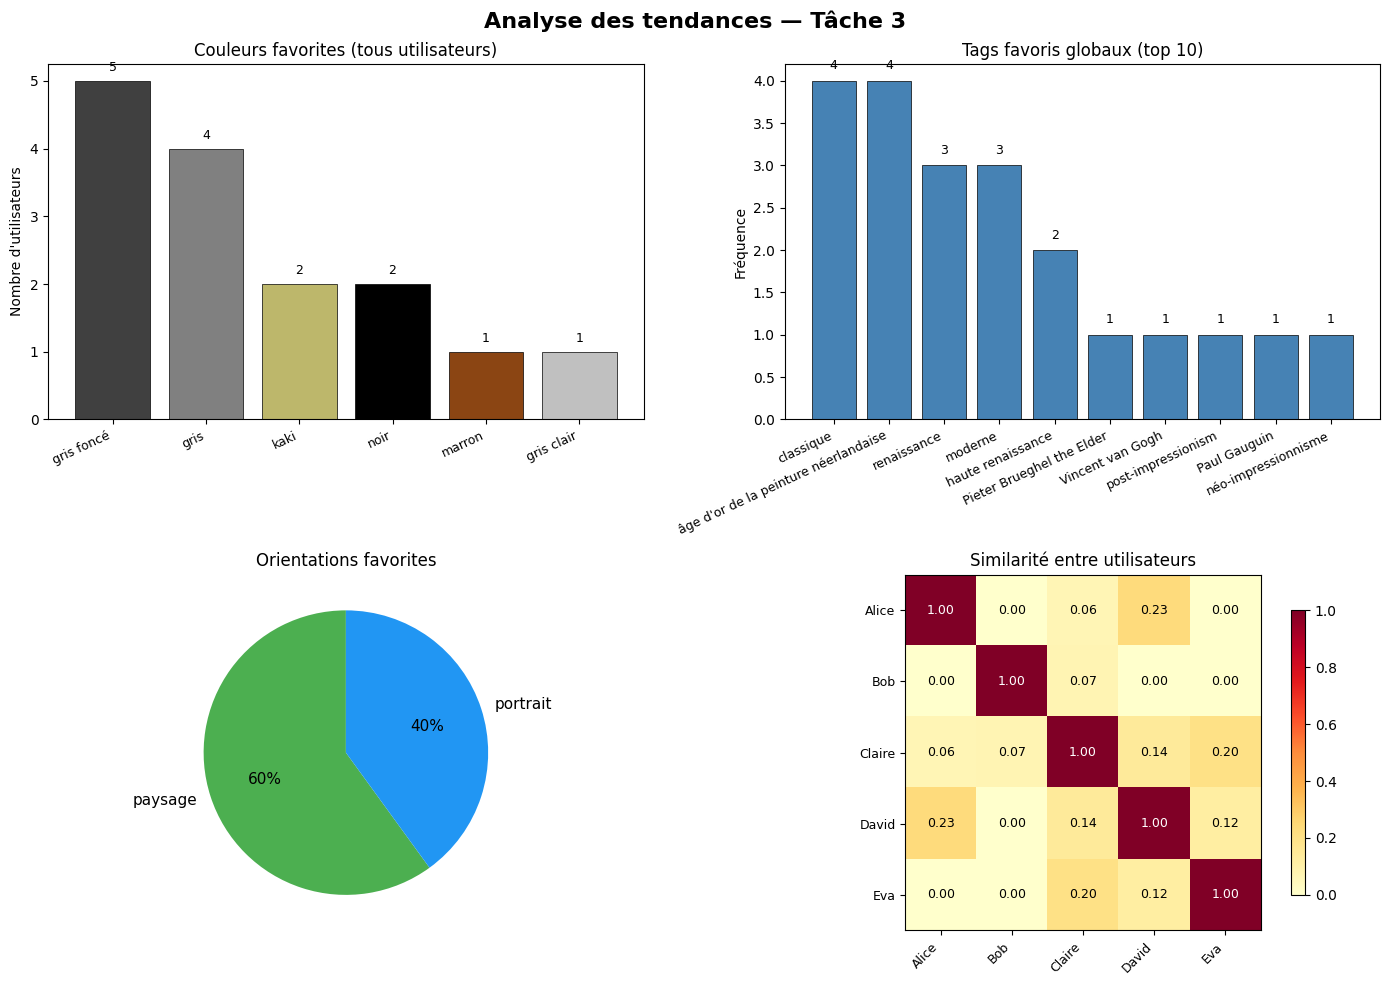

Graphique sauvegardé dans data/tendances_utilisateurs.png


In [11]:
# Cette cellule génère 4 graphiques regroupant les tendances globales des utilisateurs :
# couleurs favorites, tags les plus partagés, orientations préférées, et similarité entre profils.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Analyse des tendances — Tâche 3", fontsize=16, fontweight="bold")

# --- Graphique 1 : couleurs favorites agrégées sur tous les utilisateurs ---
# On récupère toutes les couleurs favorites de tous les profils et on les compte.
all_user_colors = []
for profile in user_profiles.values():
    all_user_colors.extend(profile["favorite_colors"])
global_colors = Counter(all_user_colors).most_common()
color_labels = [c for c, _ in global_colors]
color_counts = [n for _, n in global_colors]

# Chaque barre est coloriée avec la valeur RGB réelle de la couleur qu'elle représente,
# normalisée entre 0 et 1 comme attendu par matplotlib.
bar_colors = []
for name in color_labels:
    if name in COLOR_NAMES_FR:
        r, g, b = COLOR_NAMES_FR[name]
        bar_colors.append((r/255, g/255, b/255))
    else:
        bar_colors.append((0.5, 0.5, 0.5))

ax = axes[0, 0]
x_pos = np.arange(len(color_labels))
bars = ax.bar(x_pos, color_counts, color=bar_colors, edgecolor="black", linewidth=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(color_labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Nombre d'utilisateurs")
ax.set_title("Couleurs favorites (tous utilisateurs)")
for bar, val in zip(bars, color_counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, str(val), ha="center", va="bottom", fontsize=9)

# --- Graphique 2 : tags favoris globaux ---
# On agrège les tags favoris de tous les profils et on affiche les 10 plus fréquents.
all_user_tags = []
for profile in user_profiles.values():
    all_user_tags.extend(profile["favorite_tags"])
global_tags = Counter(all_user_tags).most_common(10)
tag_labels = [t for t, _ in global_tags]
tag_counts = [n for _, n in global_tags]

ax = axes[0, 1]
x_pos = np.arange(len(tag_labels))
bars = ax.bar(x_pos, tag_counts, color="steelblue", edgecolor="black", linewidth=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(tag_labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Fréquence")
ax.set_title("Tags favoris globaux (top 10)")
for bar, val in zip(bars, tag_counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, str(val), ha="center", va="bottom", fontsize=9)

# --- Graphique 3 : répartition des orientations favorites sous forme de camembert ---
orient_dist = Counter(p["favorite_orientation"] for p in user_profiles.values())
orient_labels = list(orient_dist.keys())
orient_counts = list(orient_dist.values())

ax = axes[1, 0]
wedges, texts, autotexts = ax.pie(
    orient_counts, labels=orient_labels, autopct="%1.0f%%",
    colors=["#4CAF50", "#2196F3", "#FF9800", "#9E9E9E"],
    startangle=90, textprops={"fontsize": 11}
)
ax.set_title("Orientations favorites")

# --- Graphique 4 : matrice de similarité entre utilisateurs (heatmap) ---
# La similarité mesure le chevauchement entre deux ensembles d'images favorites.
# Une valeur proche de 1 signifie que les deux utilisateurs aiment les mêmes images.
user_ids = list(user_profiles.keys())
n = len(user_ids)
sim_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i == j:
            sim_matrix[i, j] = 1.0
        else:
            set1 = set(user_profiles[user_ids[i]]["favorite_images"])
            set2 = set(user_profiles[user_ids[j]]["favorite_images"])
            sim_matrix[i, j] = len(set1 & set2) / len(set1 | set2) if set1 | set2 else 0

ax = axes[1, 1]
short_names = [p["name"].split("–")[0].strip() for p in user_profiles.values()]
im = ax.imshow(sim_matrix, cmap="YlOrRd", vmin=0, vmax=1)
ax.set_xticks(np.arange(n))
ax.set_yticks(np.arange(n))
ax.set_xticklabels(short_names, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(short_names, fontsize=9)
ax.set_title("Similarité entre utilisateurs")

# On affiche les valeurs numériques dans chaque cellule de la heatmap.
# La couleur du texte s'adapte au fond pour rester lisible.
for i in range(n):
    for j in range(n):
        color = "white" if sim_matrix[i, j] > 0.5 else "black"
        ax.text(j, i, f"{sim_matrix[i, j]:.2f}", ha="center", va="center",
                color=color, fontsize=9)

fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("data/tendances_utilisateurs.png", dpi=150, bbox_inches="tight")
plt.show()

print("Graphique sauvegardé dans data/tendances_utilisateurs.png")

# Tâche 4 : Visualisation des données

Au moins 8 visualisations couvrant les statistiques de la collection, l'analyse des couleurs, les préférences utilisateurs et les tags.

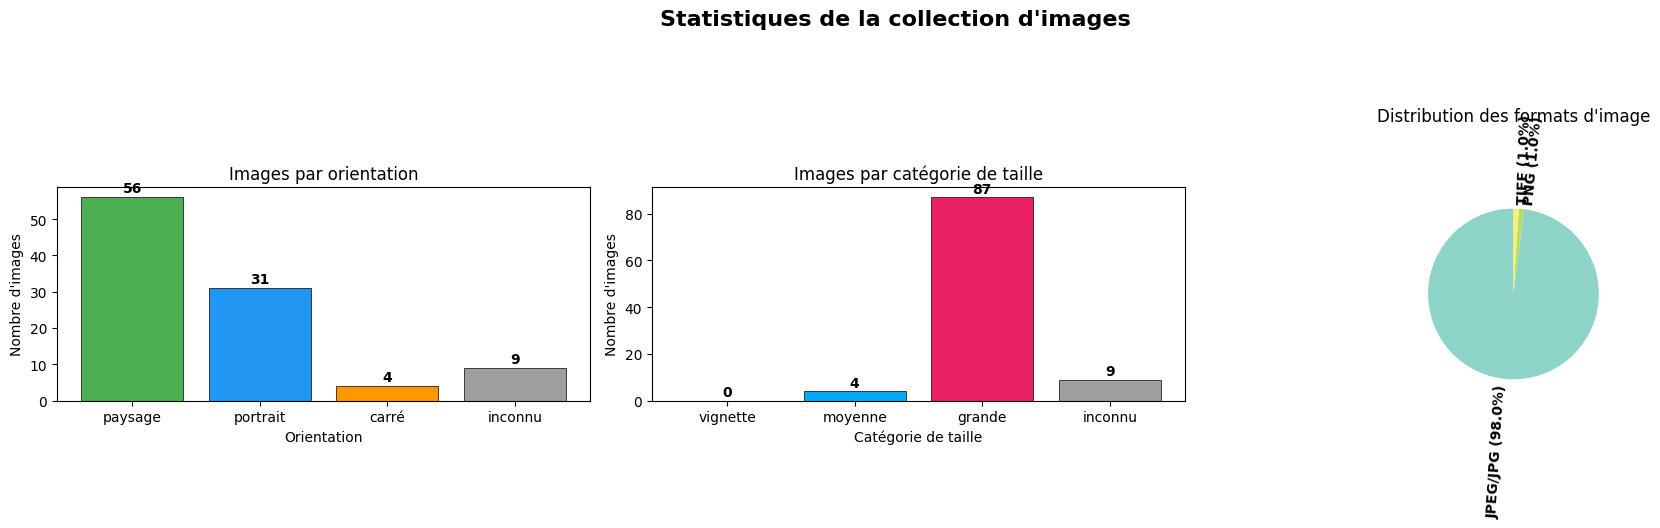

Sauvegardé : data/viz_collection_stats.png


In [12]:
# VIZ 1 : Cette cellule produit 3 graphiques : répartition par orientation, par taille, et par format d'image.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Statistiques de la collection d'images", fontsize=16, fontweight="bold", y=1.02)

# --- 1a. Nombre d'images par orientation ---
orient_counts = Counter(v["orientation"] for v in images_labels.values())
orient_order = ["paysage", "portrait", "carré", "inconnu"]
orient_vals = [orient_counts.get(o, 0) for o in orient_order]
colors_orient = ["#4CAF50", "#2196F3", "#FF9800", "#9E9E9E"]

ax = axes[0]
bars = ax.bar(orient_order, orient_vals, color=colors_orient, edgecolor="black", linewidth=0.5)
for bar, val in zip(bars, orient_vals):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(val),
        ha="center",
        va="bottom",
        fontweight="bold",
    )
ax.set_xlabel("Orientation")
ax.set_ylabel("Nombre d'images")
ax.set_title("Images par orientation")

# --- 1b. Nombre d'images par catégorie de taille ---
size_counts = Counter(v["size_category"] for v in images_labels.values())
size_order = ["vignette", "moyenne", "grande", "inconnu"]
size_vals = [size_counts.get(s, 0) for s in size_order]
colors_size = ["#FFC107", "#03A9F4", "#E91E63", "#9E9E9E"]

ax = axes[1]
bars = ax.bar(size_order, size_vals, color=colors_size, edgecolor="black", linewidth=0.5)
for bar, val in zip(bars, size_vals):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(val),
        ha="center",
        va="bottom",
        fontweight="bold",
    )
ax.set_xlabel("Catégorie de taille")
ax.set_ylabel("Nombre d'images")
ax.set_title("Images par catégorie de taille")

# --- 1c. Distribution des formats d'image (circulaire) ---
with open("data/images_metadata.json", "r", encoding="utf-8") as f:
    meta_list = json.load(f)

# On normalise les noms de formats pour regrouper JPEG et JPG sous une seule étiquette.
def normalize_format(fmt):
    if not fmt:
        return None
    fmt = str(fmt).strip().upper()
    if fmt in {"JPG", "JPEG"}:
        return "JPEG/JPG"
    return fmt

normalized_formats = [normalize_format(m.get("format")) for m in meta_list]
format_counts = Counter(fmt for fmt in normalized_formats if fmt)
fmt_labels = list(format_counts.keys())
fmt_vals = list(format_counts.values())
colors_fmt = plt.cm.Set3(np.linspace(0, 1, len(fmt_labels)))

# On construit les étiquettes du camembert avec le pourcentage de chaque format.
total_fmt = sum(fmt_vals) if fmt_vals else 1
labels_with_pct = [f"{lbl} ({val / total_fmt * 100:.1f}%)" for lbl, val in zip(fmt_labels, fmt_vals)]

ax = axes[2]
wedges, texts = ax.pie(
    fmt_vals,
    labels=labels_with_pct,
    colors=colors_fmt,
    startangle=90,
    labeldistance=1.05,
    textprops={"fontsize": 10, "fontweight": "bold"},
    rotatelabels=True,
)
ax.set_title("Distribution des formats d'image", pad=14, y=1.22)

plt.tight_layout()
plt.savefig("data/viz_collection_stats.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardé : data/viz_collection_stats.png")

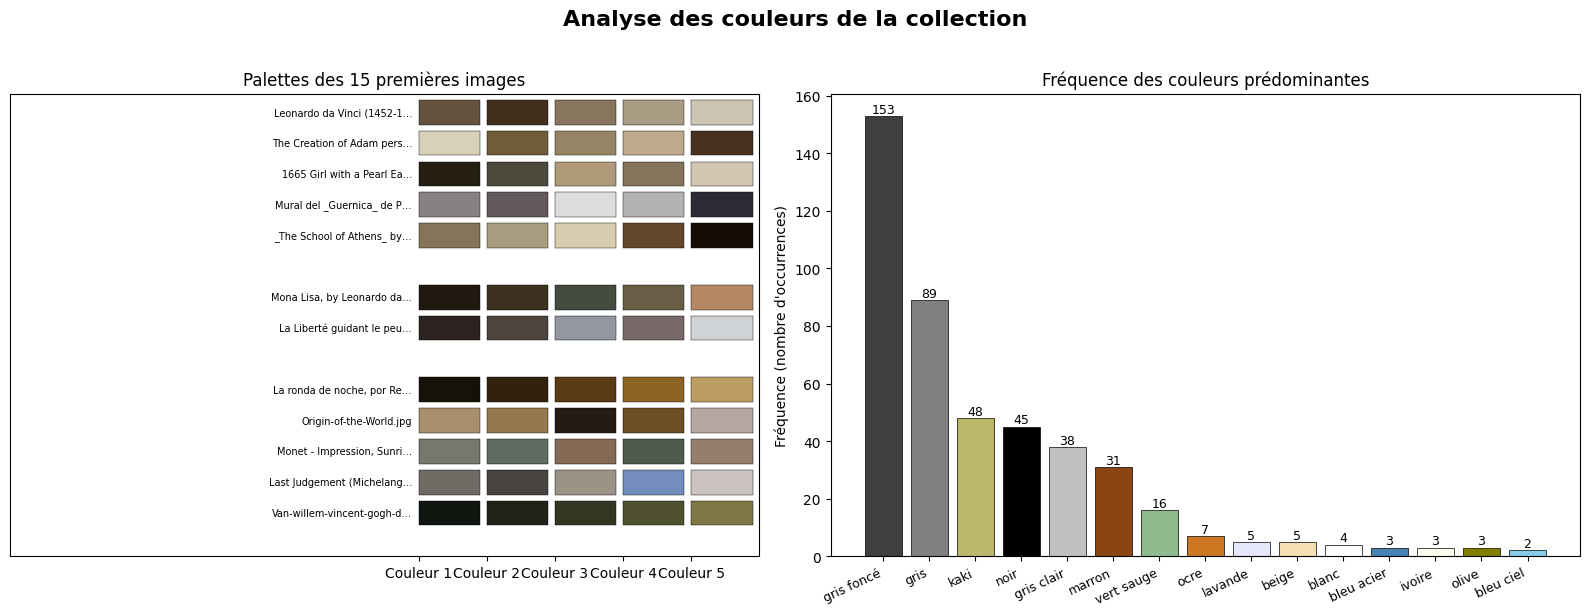

Sauvegardé : data/viz_couleurs.png


In [13]:
# VIZ 2 : Cette cellule produit 2 graphiques :
# un aperçu visuel des palettes des premières images, et un histogramme des couleurs les plus fréquentes.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Analyse des couleurs de la collection", fontsize=16, fontweight="bold", y=1.02)

# --- 2a. Palettes de couleurs des 15 premières images ---
# Chaque ligne représente une image, et chaque case colorée correspond à l'une de ses 5 couleurs KMeans,
# affichées avec leur valeur RGB réelle.
ax = axes[0]
ax.set_title("Palettes des 15 premières images")
ax.set_xlim(0, 5)
ax.set_ylim(0, 15)
ax.set_yticks([])
ax.set_xticks(range(5))
ax.set_xticklabels([f"Couleur {i+1}" for i in range(5)])

sample_keys = list(images_labels.keys())[:15]
for row_idx, img_name in enumerate(sample_keys):
    label = images_labels[img_name]
    colors = label.get("predominant_colors")
    if not colors:
        continue
    y = 14 - row_idx  # On place la première image en haut du graphique.
    for col_idx, rgb in enumerate(colors[:5]):
        color_norm = (rgb[0]/255, rgb[1]/255, rgb[2]/255)
        rect = plt.Rectangle((col_idx, y), 0.9, 0.8, facecolor=color_norm, edgecolor="black", linewidth=0.3)
        ax.add_patch(rect)
    short = img_name[:25] + "…" if len(img_name) > 25 else img_name
    ax.text(-0.1, y + 0.4, short, ha="right", va="center", fontsize=7)

ax.set_xlim(-6, 5)

# --- 2b. Histogramme des fréquences de couleurs ---
all_cnames = [c for v in images_labels.values() if v.get("color_names") for c in v["color_names"]]
color_freq = Counter(all_cnames).most_common(15)
c_labels = [c for c, _ in color_freq]
c_counts = [n for _, n in color_freq]

# Couleur réelle pour chaque barre
c_bar_colors = []
for name in c_labels:
    if name in COLOR_NAMES_FR:
        r, g, b = COLOR_NAMES_FR[name]
        c_bar_colors.append((r/255, g/255, b/255))
    else:
        c_bar_colors.append((0.5, 0.5, 0.5))

ax = axes[1]
x_pos = np.arange(len(c_labels))
bars = ax.bar(x_pos, c_counts, color=c_bar_colors, edgecolor="black", linewidth=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(c_labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Fréquence (nombre d'occurrences)")
ax.set_title("Fréquence des couleurs prédominantes")
for bar, val in zip(bars, c_counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, str(val), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("data/viz_couleurs.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardé : data/viz_couleurs.png")

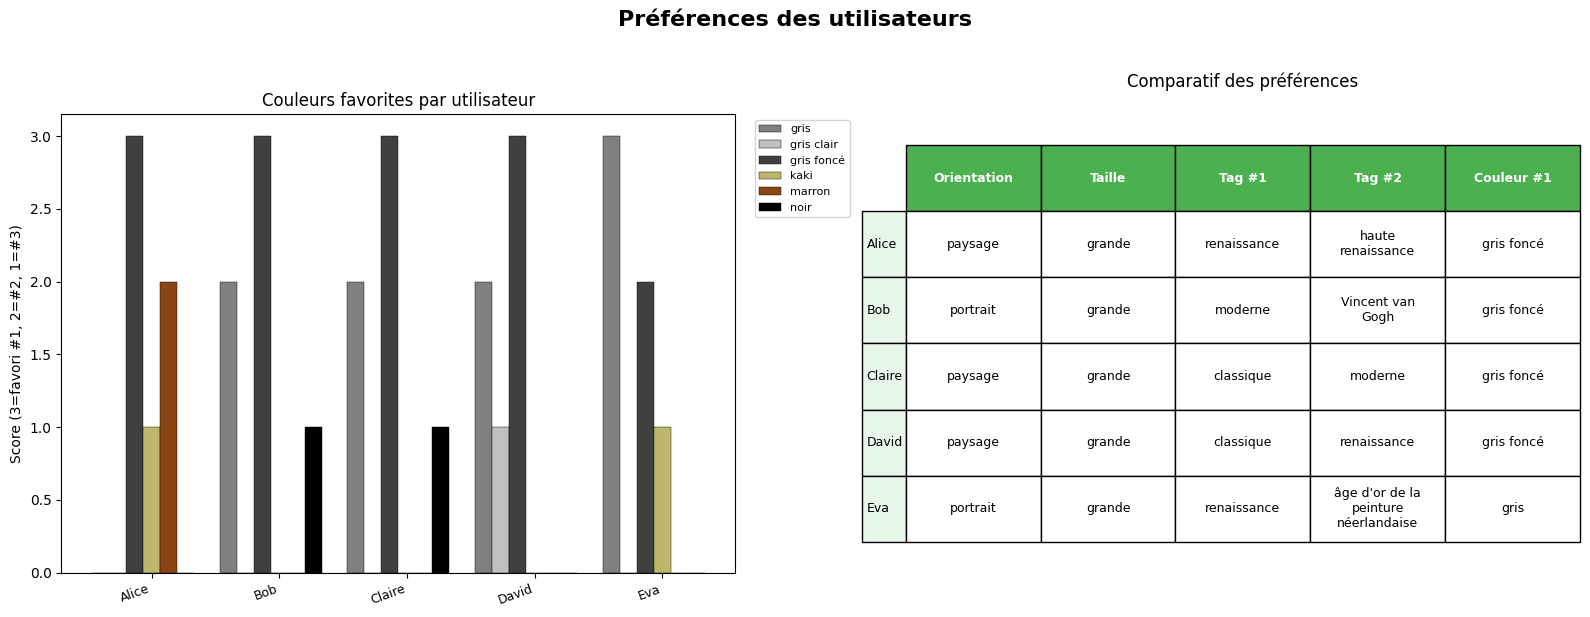

Sauvegardé : data/viz_preferences.png


In [14]:
# ══════════════════════════════════════════════════════════════
# VIZ 3 : Préférences des utilisateurs (2 graphiques)
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Préférences des utilisateurs", fontsize=16, fontweight="bold", y=1.02)

# --- 3a. Couleurs favorites par utilisateur (barres groupées) ---
ax = axes[0]
user_names = [p["name"].split("–")[0].strip() for p in user_profiles.values()]
user_ids_list = list(user_profiles.keys())

# Toutes les couleurs uniques parmi les favoris
all_fav_colors = set()
for p in user_profiles.values():
    all_fav_colors.update(p["favorite_colors"])
all_fav_colors = sorted(all_fav_colors)

x = np.arange(len(user_names))
width = 0.8 / max(len(all_fav_colors), 1)

for i, color_name in enumerate(all_fav_colors):
    vals = []
    for uid in user_ids_list:
        fav_colors = user_profiles[uid]["favorite_colors"]
        # Rang inverse : couleur #1 = 3 pts, #2 = 2 pts, #3 = 1 pt
        if color_name in fav_colors:
            rank = fav_colors.index(color_name)
            vals.append(3 - rank)
        else:
            vals.append(0)

    bar_color = (0.5, 0.5, 0.5)
    if color_name in COLOR_NAMES_FR:
        r, g, b = COLOR_NAMES_FR[color_name]
        bar_color = (r/255, g/255, b/255)

    ax.bar(x + i * width, vals, width, label=color_name, color=bar_color,
           edgecolor="black", linewidth=0.3)

ax.set_xticks(x + width * len(all_fav_colors) / 2)
ax.set_xticklabels(user_names, rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Score (3=favori #1, 2=#2, 1=#3)")
ax.set_title("Couleurs favorites par utilisateur")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

# --- 3b. Comparatif des préférences côte à côte (radar/table) ---
ax = axes[1]
categories = ["Orientation", "Taille", "Tag #1", "Tag #2", "Couleur #1"]

from textwrap import fill
def wrap_cell(val, width=14):
    if val is None or val == "-":
        return "-"
    return fill(str(val), width=width)

table_data = []
for uid in user_ids_list:
    p = user_profiles[uid]
    row = [
        wrap_cell(p["favorite_orientation"]),
        wrap_cell(p["favorite_size"]),
        wrap_cell(p["favorite_tags"][0] if len(p["favorite_tags"]) > 0 else "-"),
        wrap_cell(p["favorite_tags"][1] if len(p["favorite_tags"]) > 1 else "-"),
        wrap_cell(p["favorite_colors"][0] if len(p["favorite_colors"]) > 0 else "-"),
    ]
    table_data.append(row)

ax.axis("off")
table = ax.table(
    cellText=table_data,
    rowLabels=user_names,
    colLabels=categories,
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 4.0)
# Couleur d'en-tête
for j in range(len(categories)):
    table[0, j].set_facecolor("#4CAF50")
    table[0, j].set_text_props(color="white", fontweight="bold")
for i in range(len(user_names)):
    table[i+1, -1].set_facecolor("#E8F5E9")

ax.set_title("Comparatif des préférences", pad=20)

plt.tight_layout()
plt.savefig("data/viz_preferences.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardé : data/viz_preferences.png")

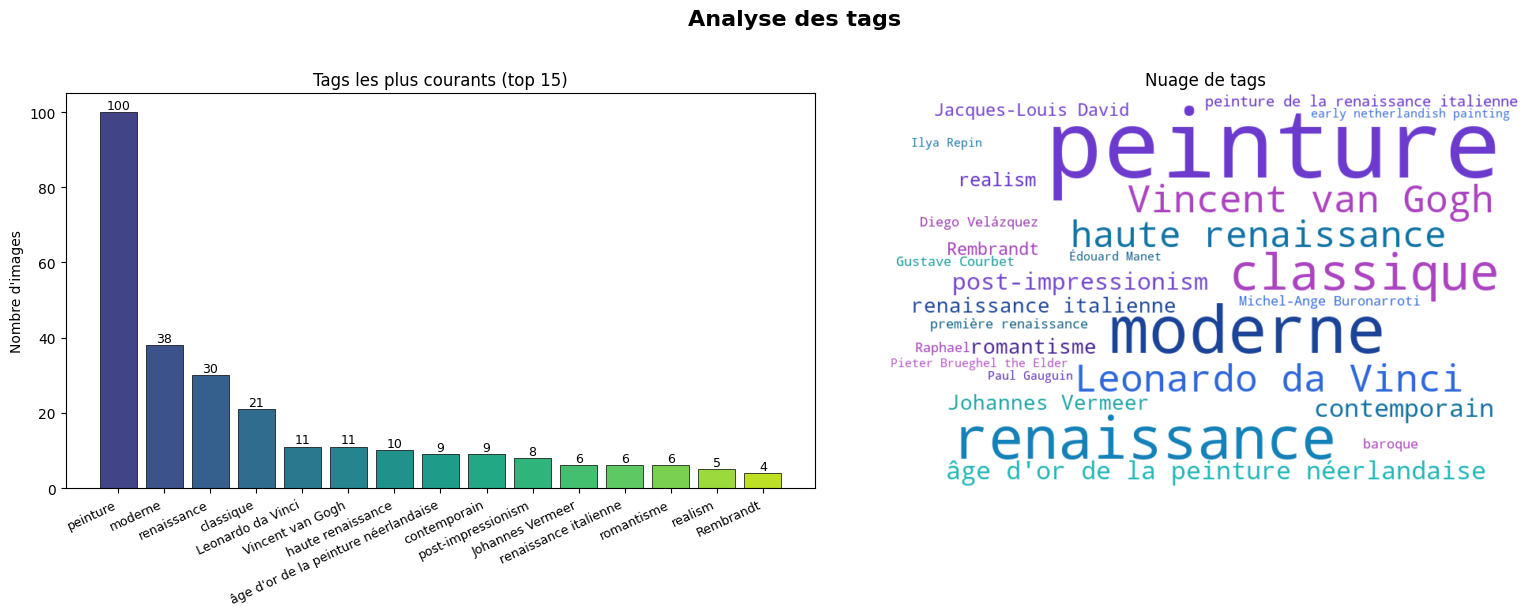

Sauvegardé : data/viz_tags.png


In [15]:
# ══════════════════════════════════════════════════════════════
# VIZ 4 : Analyse des tags (2 graphiques)
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Analyse des tags", fontsize=16, fontweight="bold", y=1.02)

# --- 4a. Tags les plus courants dans la collection ---
all_tags = [t for v in images_labels.values() if v.get("tags") for t in v["tags"]]
tag_freq = Counter(all_tags).most_common(15)
t_labels = [t for t, _ in tag_freq]
t_counts = [n for _, n in tag_freq]

ax = axes[0]
x_pos = np.arange(len(t_labels))
colors_tags = plt.cm.viridis(np.linspace(0.2, 0.9, len(t_labels)))
bars = ax.bar(x_pos, t_counts, color=colors_tags, edgecolor="black", linewidth=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(t_labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Nombre d'images")
ax.set_title("Tags les plus courants (top 15)")
for bar, val in zip(bars, t_counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, str(val), ha="center", va="bottom", fontsize=9)

# --- 4b. Nuage de mots (WordCloud) ---
ax = axes[1]
ax.axis("off")
ax.set_title("Nuage de tags")

# Construire le dictionnaire de fréquences
tag_freq_all = dict(Counter(all_tags).most_common(40))

# Palette de couleurs similaire à l'image de référence (bleu, violet, cyan, turquoise)
def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    import random
    colors = [
        "hsl(200, 80%%, %d%%)" % random.randint(30, 55),   # bleu
        "hsl(260, 60%%, %d%%)" % random.randint(35, 55),   # violet
        "hsl(180, 70%%, %d%%)" % random.randint(30, 50),   # cyan/turquoise
        "hsl(220, 70%%, %d%%)" % random.randint(35, 55),   # bleu foncé
        "hsl(290, 50%%, %d%%)" % random.randint(40, 55),   # mauve
    ]
    return random.choice(colors)

wc = WordCloud(
    width=800,
    height=500,
    background_color="white",
    max_words=40,
    max_font_size=120,
    min_font_size=14,
    prefer_horizontal=1.0,
    relative_scaling=0.5,
    color_func=color_func,
    collocations=False,
    margin=4,
    random_state=42,
)
wc.generate_from_frequencies(tag_freq_all)

ax.imshow(wc, interpolation="bilinear")

plt.tight_layout()
plt.savefig("data/viz_tags.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sauvegardé : data/viz_tags.png")

# Tâche 5 : Systeme de recommandation

Implementer un systeme qui recommande des images aux utilisateurs en fonction de leurs preferences.

In [16]:
# Préparation des features pour la recommandation (utilisées par l'approche hybride)
import pandas as pd
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer, LabelEncoder
from sklearn.ensemble import RandomForestClassifier


# Cette fonction convertit le dictionnaire images_labels en une matrice exploitable par les algorithmes
# Chaque image devient une ligne, et chaque caractéristique (orientation, taille, couleurs, tags)
# devient une ou plusieurs colonnes encodées.
def _prepare_feature_matrix(images_labels):
    # On construit d'abord un DataFrame à partir du dictionnaire de labels.
    rows = []
    for img_name, info in images_labels.items():
        rows.append({
            "image": img_name,
            "orientation": info.get("orientation", "inconnu") or "inconnu",
            "size_category": info.get("size_category", "inconnu") or "inconnu",
            "colors": info.get("color_names") or [],
            "tags": info.get("tags") or [],
        })
    df = pd.DataFrame(rows)

    # LabelEncoder convertit une catégorie simple (ex: "portrait" → 1).
    # On l'utilise pour les colonnes à valeur unique comme l'orientation et la taille.
    orient_le = LabelEncoder()
    size_le = LabelEncoder()
    orient_encoded = orient_le.fit_transform(df["orientation"])
    size_encoded = size_le.fit_transform(df["size_category"])
    orient_df = pd.DataFrame({"orient_le": orient_encoded})
    size_df = pd.DataFrame({"size_le": size_encoded})

    # Encodage multivalué (tags, couleurs)
    tag_enc = MultiLabelBinarizer()
    color_enc = MultiLabelBinarizer()
    tags_mat = tag_enc.fit_transform(df["tags"])
    colors_mat = color_enc.fit_transform(df["colors"])
    tags_df = pd.DataFrame(tags_mat, columns=[f"tag_{t}" for t in tag_enc.classes_])
    colors_df = pd.DataFrame(colors_mat, columns=[f"color_{c}" for c in color_enc.classes_])

    # On concatène toutes les colonnes encodées en une seule matrice X.
    X = pd.concat([orient_df, size_df, tags_df, colors_df], axis=1)
    return df.reset_index(drop=True), X.reset_index(drop=True)


# Cette fonction entraîne un classifieur Random Forest pour un utilisateur donné.
# Le modèle apprend à distinguer les images aimées (1) des autres (0) selon leurs features.
def _train_user_classifier(user_id, df_feat, X):
    favorites = set(user_profiles[user_id]["favorite_images"])
    y = df_feat["image"].apply(lambda n: 1 if n in favorites else 0)

    # Si l'utilisateur a trop peu de favoris ou aime toutes les images,
    # le classifieur ne peut pas apprendre : on renvoie None pour refaire
    if y.sum() < 2 or y.sum() >= len(y):
        return None, y

    # Dans notre cas, il y a peu d'images favorites (classe 1) et beaucoup d'images non favorites (classe 0).
    # Sans rééquilibrage, le modèle pourrait surtout apprendre à prédire 0 partout,
    # car ce serait statistiquement la classe la plus fréquente.
    # class_weight="balanced_subsample" donne donc plus de poids aux favoris pendant l'entraînement
    # pour qu'ils comptent davantage dans les décisions des arbres de la forêt.
    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        class_weight="balanced_subsample",
    )
    model.fit(X, y)
    return model, y

In [17]:
# approche C : hybride -->
# 1) un score de contenu, basé sur les caractéristiques explicites des images
#    comme les couleurs, les tags, la taille ou l'orientation ;
# 2) un score de cluster, basé sur des groupes d'images similaires obtenus avec KMeans.
# L'idée est donc de recommander à la fois des images qui ressemblent aux goûts connus
# de l'utilisateur, et des images situées dans les mêmes zones que ses favoris dans l'espace des features.
def _fit_clusters(X, n_clusters=8):
    # On évite de demander plus de clusters qu'il n'existe d'images.
    k = min(n_clusters, len(X))
    if k < 2:
        return None, np.zeros(len(X), dtype=int)

    # KMeans attribue à chaque image un identifiant de cluster.
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    clusters = km.fit_predict(X)
    return km, clusters

# Cette fonction calcule des recommandations personnalisées pour un utilisateur donné.
# Elle combine un score contenu et un score cluster, puis trie les images pas encore favorites
def recommend_images_hybrid(user_id, n_recommendations=5, alpha=0.6, n_clusters=8):
    if user_id not in user_profiles:
        raise ValueError(f"Utilisateur inconnu: {user_id}")

    # On prépare les features des images et, si possible, un modèle supervisé pour cet utilisateur.
    df_feat, X = _prepare_feature_matrix(images_labels)
    model, _ = _train_user_classifier(user_id, df_feat, X)
    favorites = set(user_profiles[user_id]["favorite_images"])
    prefs = user_preferences.get(user_id, {})

    # Score contenu
    if model is not None:
        content_scores = model.predict_proba(X)[:, 1]
    else:
        # Sinon, on utilise un score plus simple basé directement sur les préférences déclarées.
        pref_tags = set([t.lower() for t in prefs.get("preferred_tags", [])])
        pref_colors = set(prefs.get("preferred_colors", []))
        pref_orient = prefs.get("preferred_orientation")
        tmp = []
        for _, row in df_feat.iterrows():
            s = 0

            # Bonus si l'orientation correspond.
            if pref_orient and row["orientation"] == pref_orient:
                s += 1.0

            # Bonus selon le nombre de couleurs et tags en commun avec les préférences utilisateur.
            colors = set(row["colors"])
            tags = set([t.lower() for t in row["tags"]])
            s += 0.7 * len(colors & pref_colors)
            s += 0.8 * len(tags & pref_tags)
            tmp.append(s)
        content_scores = np.array(tmp, dtype=float)

    # Score cluster : on regarde dans quels clusters tombent les images favorites de l'utilisateur.
    # Une image reçoit un score élevé si elle appartient à un cluster souvent présent parmi ses favoris.
    km, clusters = _fit_clusters(X, n_clusters=n_clusters)
    df_feat = df_feat.copy()
    df_feat["cluster"] = clusters
    cluster_weights = Counter(df_feat[df_feat["image"].isin(favorites)]["cluster"])
    denom = sum(cluster_weights.values()) or 1
    cluster_scores = np.array([cluster_weights.get(c, 0) / denom for c in clusters])

# Le score final mélange les deux composantes.
# alpha=0.6 signifie ici qu'on donne 60% d'importance au contenu
# et 40% au voisinage cluster.
    hybrid_score = alpha * content_scores + (1 - alpha) * cluster_scores
    df_feat["score"] = hybrid_score

    # On retire les images déjà favorites puis on garde les meilleures candidates.
    candidates = df_feat[~df_feat["image"].isin(favorites)].sort_values("score", ascending=False)

    # On construit enfin une petite explication textuelle pour chaque recommandation.
    recs = []
    for _, row in candidates.head(max(n_recommendations, 1)).iterrows():
        reasons = []
        if prefs.get("preferred_orientation") and row["orientation"] == prefs["preferred_orientation"]:
            reasons.append(f"orientation {row['orientation']}")

        common_tags = set([t.lower() for t in row["tags"]]) & set([t.lower() for t in prefs.get("preferred_tags", [])])
        if common_tags:
            reasons.append(f"tags {', '.join(sorted(common_tags))}")

        common_colors = set(row["colors"]) & set(prefs.get("preferred_colors", []))
        if common_colors:
            reasons.append(f"couleurs {', '.join(sorted(common_colors))}")

        if km is not None:
            reasons.append(f"cluster {row['cluster']} proche des favoris")

        if not reasons:
            reasons.append("proximité hybride contenu+clusters")

        recs.append((row["image"], "Explications : " + "; ".join(reasons)))

    return recs

In [18]:
# Exemple d'appel hybride sur tous les utilisateurs
for uid, profile in user_profiles.items():
    print(f"Recommandations hybrides pour {uid} ({profile['name']}):\n")
    recs = recommend_images_hybrid(uid, n_recommendations=6, alpha=0.6, n_clusters=8)
    for img, reason in recs:
        print(f"- {img} — {reason}")
    print("\n" + "-"*60 + "\n")

Recommandations hybrides pour user_001 (Alice – Amatrice de Renaissance):

- Leonardo da Vinci (1452-1519) - The Last Supper (1495-1498).jpg — Explications : orientation paysage; tags renaissance; cluster 4 proche des favoris
- Jheronimus Bosch 023.jpg — Explications : orientation paysage; tags renaissance; cluster 4 proche des favoris
- Van Eyck - Arnolfini Portrait.jpg — Explications : tags renaissance; cluster 4 proche des favoris
- Sainte Anne Leonard.jpg — Explications : tags renaissance; cluster 4 proche des favoris
- Mona Lisa, by Leonardo da Vinci, from C2RMF natural color.jpg — Explications : tags renaissance; cluster 4 proche des favoris
- Leonardo, Madonna Benois.JPG — Explications : tags renaissance; cluster 4 proche des favoris

------------------------------------------------------------

Recommandations hybrides pour user_002 (Bob – Fan d'art moderne):

- Vincent van Gogh - Starry Night - Google Art Project.jpg — Explications : tags moderne; cluster 1 proche des favoris


# Tâche 6 : Tests

Verifier que votre systeme fonctionne correctement.

In [19]:
# Tâche 6 :
# On teste à la fois l'intégrité des fichiers, la validité des recommandations
# et quelques métriques simples de qualité.


# Cette fonction recharge le fichier JSON des métadonnées et le transforme en dictionnaire
# par nom de fichier, pour faciliter les vérifications ultérieures.
def _load_meta_map():
    meta_path = os.path.join("data", "images_metadata.json")
    if not os.path.exists(meta_path):
        return {}
    with open(meta_path, "r", encoding="utf-8") as f:
        meta_list = json.load(f)
    return {m.get("nom_fichier"): m for m in meta_list}


# vérifie que les données de base du projet sont cohérentes :
# assez d'images, fichiers présents sur le disque, métadonnées disponibles,
# et dimensions d'images valides.
def test_data_integrity(min_images=100):
    meta_map = _load_meta_map()
    assert len(images_labels) >= min_images, f"Il faut au moins {min_images} images, trouvé {len(images_labels)}"

    missing_files = [img for img in images_labels if not os.path.exists(os.path.join(IMG_FOLDER, img))]
    assert not missing_files, f"Fichiers manquants: {missing_files[:5]}"

    missing_meta = [img for img in images_labels if img not in meta_map]
    assert not missing_meta, f"Métadonnées manquantes pour: {missing_meta[:5]}"

    bad_dims = [
        img for img, m in meta_map.items()
        if m.get("largeur") is not None and m.get("largeur") <= 0
        or m.get("hauteur") is not None and m.get("hauteur") <= 0
    ]
    assert not bad_dims, f"Dimensions négatives ou nulles: {bad_dims[:5]}"


# vérifie que la fonction de recommandation renvoie bien le bon nombre d'images
# et que les couleurs stockées dans les labels restent des RGB valides entre 0 et 255.
def test_functional_recommendations(user_id, n_recs=5):
    recs = recommend_images_hybrid(user_id, n_recommendations=n_recs)
    assert len(recs) == n_recs, f"Doit retourner {n_recs} recos"

    for img, _ in recs:
        colors = images_labels.get(img, {}).get("predominant_colors")
        if colors:
            for rgb in colors:
                assert all(0 <= c <= 255 for c in rgb), f"RGB invalide pour {img}: {rgb}"


# C'est notre règl pertinence.
# Une recommandation est considérée pertinente si elle partage au moins un critère important
# avec les préférences de l'utilisateur : orientation, couleur, tag, ou justification textuelle.
def _is_relevant_for_user(user_id, img, reason=""):
    prefs = user_preferences.get(user_id, {})
    pref_colors = set(prefs.get("preferred_colors", []))
    pref_tags = set([t.lower() for t in prefs.get("preferred_tags", [])])
    pref_orient = prefs.get("preferred_orientation")

    colors = set(images_labels.get(img, {}).get("color_names") or [])
    tags = set([t.lower() for t in images_labels.get(img, {}).get("tags", [])])
    orient = images_labels.get(img, {}).get("orientation")

    orient_match = bool(pref_orient and orient == pref_orient)
    color_match = bool(pref_colors and (colors & pref_colors))
    tag_match = bool(pref_tags and (tags & pref_tags))
    reason_match = "couleur" in reason or "color" in reason or "tag" in reason or "orientation" in reason

    return orient_match or color_match or tag_match or reason_match


# Ce test vérifie qu'on ne recommande pas une image déjà favorite
# et que chaque recommandation a bien un lien avec le profil utilisateur.
def test_reco_quality(user_id, n_recs=5):
    favorites = set(user_profiles[user_id]["favorite_images"])
    recs = recommend_images_hybrid(user_id, n_recommendations=n_recs)
    for img, reason in recs:
        assert img not in favorites, f"{img} est déjà favori"
        assert _is_relevant_for_user(user_id, img, reason), f"Reco sans lien clair pour {img}"
    return recs


# Cette fonction calcule trois métriques classiques d'évaluation :
# Precision@K : parmi les K recommandations proposées, combien sont pertinentes ?
# Recall@K : parmi toutes les images pertinentes possibles, combien ont été retrouvées ?
# F1@K : compromis global entre précision et rappel.
def compute_reco_metrics(user_id, n_recs=5):
    favorites = set(user_profiles[user_id]["favorite_images"])
    recs = recommend_images_hybrid(user_id, n_recommendations=n_recs)

    relevant_in_recs = sum(1 for img, reason in recs if _is_relevant_for_user(user_id, img, reason))

    non_favorites = [img for img in images_labels if img not in favorites]
    relevant_pool = sum(1 for img in non_favorites if _is_relevant_for_user(user_id, img, ""))

    precision_at_k = relevant_in_recs / max(len(recs), 1)
    recall_at_k = relevant_in_recs / max(relevant_pool, 1)
    f1_at_k = 0.0
    if precision_at_k + recall_at_k > 0:
        f1_at_k = 2 * precision_at_k * recall_at_k / (precision_at_k + recall_at_k)

    return {
        "k": len(recs),
        "relevant_in_recs": relevant_in_recs,
        "relevant_pool": relevant_pool,
        "precision_at_k": precision_at_k,
        "recall_at_k": recall_at_k,
        "f1_at_k": f1_at_k,
    }


# Cette fonction exécute toute la batterie de tests sur un utilisateur exemple,
# puis affiche quelques recommandations ainsi que les métriques calculées.
def run_all_tests():
    example_user = list(user_profiles.keys())[4]  # choisir sur quel utilisateur tester
    test_data_integrity(min_images=80)  # seuil un peu plus tolérant si quelques téléchargements manquent
    test_functional_recommendations(example_user, n_recs=5)
    recs = test_reco_quality(example_user, n_recs=5)
    metrics = compute_reco_metrics(example_user, n_recs=5)

    print("Tests OK ")
    print("Exemple de recommandations (qualité):")
    for img, reason in recs:
        print(f"- {img}: {reason}")

    print("\nMétriques recommandation:")
    print(f"- Precision@{metrics['k']}: {metrics['precision_at_k']:.3f} (part des recommandations proposées qui sont pertinentes)")
    print(f"- Recall@{metrics['k']}: {metrics['recall_at_k']:.3f} (part des images pertinentes retrouvées parmi toutes les pertinentes possibles)")
    print(f"- F1@{metrics['k']}: {metrics['f1_at_k']:.3f} (moyenne harmonique entre précision et rappel)")


# Explication de ce que j'avais eu à l'utilisation :
# Precision@5 = 1.000
# Ça, ça veut dire que les 5 images recommandées sont toutes jugées pertinentes par notre règle
# On a donc relevant_in_recs = 5 et K=5 ce qui nous fait 5/5 = 1.0.
# 
# Ensuite on a Recall@5 = 0.057
# Ici, il existe beaucoup plus d’images pertinentes dans le pool total ("relevant_pool" grand)
# et on en récupères que 5 car on ne recommandes que 5 images
# Exemple : si on a relevant_pool = 88, alors 5/88 = 0.057. --> C'est pour ça qu'on a un score assez bas
# 
# F1@5 = 0.109
# Le F1 combine précision et rappel.
# Avec P=1.0 et R=0.057 on obtient donc F1 = 2*1*0.057/(1+0.057) = 0.109.



In [20]:
# Exécution des tests
run_all_tests()

Tests OK 
Exemple de recommandations (qualité):
- Johannes Vermeer - The Astronomer - 1668.jpg: Explications : tags peinture; couleurs gris, kaki; cluster 6 proche des favoris
- Johannes Vermeer - Gezicht op huizen in Delft, bekend als 'Het straatje' - Google Art Project.jpg: Explications : tags peinture; couleurs gris, kaki; cluster 6 proche des favoris
- La ronda de noche, por Rembrandt van Rijn.jpg: Explications : tags peinture; couleurs kaki; cluster 0 proche des favoris
- Jan Vermeer - The Art of Painting - Google Art Project.jpg: Explications : tags peinture; couleurs gris; cluster 6 proche des favoris
- Raffaello Sanzio - La Fornarina (ca. 1519-1520).jpg: Explications : tags peinture; couleurs gris; cluster 4 proche des favoris

Métriques recommandation:
- Precision@5: 1.000 (part des recommandations proposées qui sont pertinentes)
- Recall@5: 0.057 (part des images pertinentes retrouvées parmi toutes les pertinentes possibles)
- F1@5: 0.109 (moyenne harmonique entre précision e